In [107]:
%pip install seaborn

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("data/diabetic_data.csv")
df.head()

Note: you may need to restart the kernel to use updated packages.


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [108]:
#Change ? to missiing values.
df = df.replace('?', pd.NA)

#Check how many missing values in each column
df.isna().sum()


encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [109]:
#Want to make following columns nominal categorical data (w/o order).
category_columns = ['race', 'gender', 'admission_type_id', 'discharge_disposition_id',
                    'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1',
                    'diag_2', 'diag_3', 'A1Cresult', 'metformin', 
                    'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide',
                    'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 
                    'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
                    'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone',
                    'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 
                    'readmitted'] 

df[category_columns] = df[category_columns].astype('category')

#Ages and weight are in a range like [0-10), Want ordered categorial.
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)'
             , '[60-70)', '[70-80)', '[80-90)', '[90-100)']
df['age'] = pd.Categorical(df['age'], categories=age_order, ordered=True)

weight_order = ['[0-25)', '[25-50)', '[50-75)', '[75-100)', '[100-125)', '[125-150)',
                '[150-175)', '[175-200)', '>200']
df['weight'] = pd.Categorical(df['weight'], categories=weight_order, ordered = True)

#max_glu_serum: Indicates the range of the result or if the test was not taken. About 95% of entries had None.
max_glu_serumlevels = ['Norm', '>200', '>300']
df['max_glu_serum'] = pd.Categorical(df['max_glu_serum'], categories=max_glu_serumlevels, ordered=True)

# Check the data types to make sure its fine. 
# df.dtypes

#Make encounter_id and pantient_id strings:
df['encounter_id'] = df['encounter_id'].astype('str')
df['patient_nbr'] = df['patient_nbr'].astype('str')


In [110]:
dtypes = df.dtypes

#Gather all numerical columns into a list
numeric_col = []

i = 0 
while i < len(dtypes):
    if dtypes.iloc[i] == 'int64':
        numeric_col.append(dtypes.index[i])
    i = i + 1

#numeric_col


In [124]:
#Spearman correlation. To see if the numeric columns have a monotonic relationship.

correlations = df[numeric_col].corr(method = 'spearman')
correlations.round(3)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000,0.337,0.187,0.465,-0.013,-0.001,0.092,0.237
num_lab_procedures,0.337,1.000,0.023,0.252,-0.024,0.006,0.041,0.169
num_procedures,0.187,0.023,1.000,0.352,-0.024,-0.046,-0.064,0.067
num_medications,0.465,0.252,0.352,1.000,0.074,0.044,0.099,0.294
number_outpatient,-0.013,-0.024,-0.024,0.074,1.000,0.177,0.156,0.113
number_emergency,-0.001,0.006,-0.046,0.044,0.177,1.000,0.222,0.092
number_inpatient,0.092,0.041,-0.064,0.099,0.156,0.222,1.000,0.136
number_diagnoses,0.237,0.169,0.067,0.294,0.113,0.092,0.136,1.000


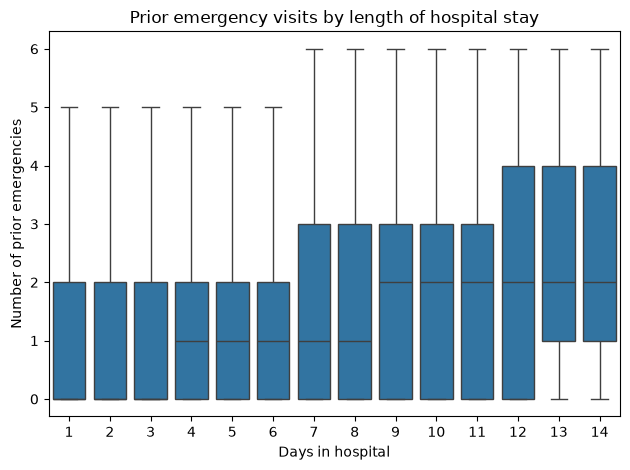